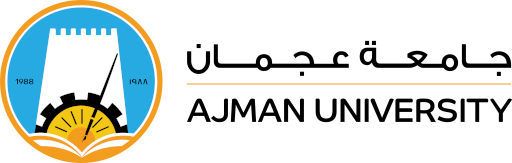

<table style="margin-left: 0; margin-right: auto;">
  <tr>
    <td><b>College:</b></td>
    <td>Engineering and Information Technology</td>
  </tr>
  <tr>
    <td><b>Department:</b></td>
    <td>Information Technology</td>
  </tr>
  <tr>
    <td><b>Program:</b></td>
    <td>Data Analytics and Artificial Intelligence</td>
  </tr>
  <tr>
    <td><b>Academic Semester:</b></td>
    <td>Spring 2025-2026</td>
  </tr>
  <tr>
    <td><b>Course:</b></td>
    <td>DAT405 Machine Learning Lab</td>
  </tr>
  <tr>
    <td><b>Course Instructor:</b></td>
    <td>Prof. Mahmoud AlShboul</td>
  </tr>
</table>


Student ID: ______________________ <br />
Student Name: _______________________

# **Lab 8 - RNN Classifier**

## Recurrent Neural Networks (RNNs)

Recurrent Neural Networks (RNNs) are a type of deep learning model designed to process sequential data, like text or time series, by using feedback loops to maintain a "memory" of previous inputs. This allows them to consider past information to influence current predictions, unlike standard neural networks. RNNs are used in applications such as natural language processing, speech recognition, and time-series forecasting.

The key difference between a traditional neural network (often called a feedforward neural network) and an RNN (Recurrent Neural Network) is how they handle data and memory.

1. **Data handling**
    * Traditional Neural Network
        * Processes fixed-size, independent inputs
        * Assumes no relationship between inputs
        * Example: classifying an image
        * Each input is handled separately

    * RNN (Recurrent Neural Network)
        * Designed for sequences
        * Inputs are dependent on previous inputs
        * Example: processing a sentence word by word
        * Each step depends on what came before


2. **Memory**
    * Traditional NN
        * No memory
        * Output depends only on current input
    * RNN
        * Has memory (hidden state)
        * Output depends on:
            * current input
            * previous inputs (via stored state)


3. **Architecture**
    * Traditional NN
        * Straight flow:
        * Input → Hidden Layers → Output
    * RNN
        * Has loops (feedback connections):
        * Input → Hidden → Output → feeds back into itself
        * This loop is what enables remembering past information.


4. **Use cases**
    * Traditional NN
        * Image classification
        * Tabular data
        * Basic regression/classification
    * RNN
        * Text (NLP)
        * Speech
        * Time series
        * Anything order-dependent


5. **Limitations**
    * Traditional NN
        * Can’t model sequences or context
    * RNN
        * Can struggle with long-term memory (vanishing gradients)
        * Slower due to sequential processing

More information at: https://www.ibm.com/think/topics/recurrent-neural-networks


## Digits Dataset
**Nature of Data**: The digits dataset is a collection of handwritten digits.

**Content**: It consists of 1,797 8x8 images, meaning each image is represented by a 64-dimensional vector of pixel values. Each pixel value ranges from 0 (meaning white) to 16 (meaning black), giving a grayscale pixel representation.

**Labels**: Each image corresponds to a digit from 0 to 9, providing a total of 10 classes. The objective is to classify each image into one of these ten classes.

**Use-case**: The dataset is typically used for classification problems in machine learning, especially as an introductory dataset for image classification. It is a simpler and smaller alternative to other handwritten digit datasets, like the MNIST dataset.

**Visualization**: The images can be visualized as grayscale images, and since they are small (8x8), they appear quite pixelated. But even at this resolution, numbers can be recognized, which makes it a good dataset for learning purposes.

In [1]:
# Import necessary libraries
import numpy as np
import tensorflow as tf
from keras import layers, models
# For loading built-in datasets
from sklearn import datasets
# For splitting the dataset into training/testing sets
from sklearn.model_selection import train_test_split
# For converting categorical labels into one-hot encoded format
from sklearn.preprocessing import OneHotEncoder
# For plotting the graphs
import matplotlib.pyplot as plt



I0000 00:00:1775107922.590802   13907 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1775107922.809060   13907 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1775107928.344472   13907 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# --------------------------------------------------------------
# 1. Load the digits dataset
# --------------------------------------------------------------
# The digits dataset is a small dataset containing images of handwritten digits (0–9).
# Each image is 8x8 pixels.
digits = datasets.load_digits()

# --------------------------------------------------------------
# 2. Reshape the image data
# --------------------------------------------------------------
# 'digits.images' contains images of shape (n_samples, 8, 8).
# Many machine learning models expect data in a 2D array (n_samples, n_features),
# so we reshape each 8x8 image (64 pixels) into a 1D vector of length 64.
data = digits.images.reshape((len(digits.images), 64))

# --------------------------------------------------------------
# 3. Prepare the target labels
# --------------------------------------------------------------
# 'digits.target' contains integer class labels (0–9).
# Reshape it to a 2D array with one column so it fits the encoder’s expected input shape.
target = digits.target.reshape(-1, 1)

# --------------------------------------------------------------
# 4. One-hot encode the target labels
# --------------------------------------------------------------
# Machine learning models (especially neural networks) often work better with one-hot encoded labels.
# Example: digit "3" becomes [0, 0, 0, 1, 0, 0, 0, 0, 0, 0].
encoder = OneHotEncoder(sparse_output=False)   # Set sparse_output=False to get a dense NumPy array instead of a sparse matrix
target_onehot = encoder.fit_transform(target)  # Fit encoder on target data and transform labels into one-hot format

# --------------------------------------------------------------
# 5. Split the dataset into training and testing sets
# --------------------------------------------------------------
# 'test_size=0.2' means 20% of the data will be used for testing, and 80% for training.
# 'random_state=42' ensures reproducibility (the split will be the same every time you run the code).
x_train, x_test, y_train, y_test = train_test_split(
    data, target_onehot, test_size=0.2, random_state=42
)


In [3]:
# --------------------------------------------------------------
# 1. Build a Sequential model
# --------------------------------------------------------------
# The Sequential API allows us to build a neural network layer-by-layer.
model = models.Sequential([
    
    # ----------------------------------------------------------
    # Reshape Layer
    # ----------------------------------------------------------
    # Input data shape: (64,) since each image has 8x8 = 64 pixels flattened.
    # RNNs expect sequential input (timesteps, features), so we reshape it to (8, 8)
    # — treating each row of the 8x8 image as one "time step" of 8 features.
    layers.Reshape((8, 8), input_shape=(64,)),

    # ----------------------------------------------------------
    # First SimpleRNN Layer
    # ----------------------------------------------------------
    # This RNN layer processes the 8 timesteps, each with 8 features.
    # It has 128 recurrent units (neurons) and uses ReLU activation.
    # `return_sequences=True` means it outputs the full sequence (not just the final state),
    # so the next RNN layer receives sequence data as input.
    layers.SimpleRNN(128, activation='relu', return_sequences=True),

    # ----------------------------------------------------------
    # Second SimpleRNN Layer
    # ----------------------------------------------------------
    # This RNN layer takes the output sequence from the previous RNN and summarizes it
    # into a single output vector (since `return_sequences=False` by default).
    # It uses 64 recurrent units to capture temporal dependencies.
    layers.SimpleRNN(64, activation='relu'),

    # ----------------------------------------------------------
    # Output Layer (Dense)
    # ----------------------------------------------------------
    # Fully connected layer with 10 neurons — one for each digit class (0–9).
    # The softmax activation converts raw scores into probabilities that sum to 1.
    layers.Dense(10, activation='softmax')
])

# --------------------------------------------------------------
# 2. Compile the model
# --------------------------------------------------------------
# - Optimizer: 'adam' adjusts learning rate adaptively during training.
# - Loss: 'categorical_crossentropy' is used for multi-class classification
#   when labels are one-hot encoded.
# - Metrics: 'accuracy' measures how often predictions match true labels.
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# --------------------------------------------------------------
# 3. Display model summary
# --------------------------------------------------------------
# Shows each layer, its output shape, and number of parameters (weights).
model.summary()


/home/ali/Documents/AU/Assistant Instructor/202520/DAT405 Machine Learning/Labs/.venv/lib/python3.13/site-packages/keras/src/layers/reshaping/reshape.py:38: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 8, 8)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 8, 128)         │        17,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,538 (119.29 KB)

 Trainable params: 30,538 (119.29 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# --------------------------------------------------------------
# Train the RNN model
# --------------------------------------------------------------

# 'fit()' starts the training process for the neural network.
# It uses the training data to adjust model weights and minimize the loss function.
history = model.fit(
    x_train,                # Training input features (reshaped image data)
    y_train,                # True target labels (one-hot encoded)
    epochs=10,              # Number of complete passes through the entire training dataset
    batch_size=32,          # Number of samples processed before the model updates its weights
    validation_split=0.1    # 10% of training data will be used for validation (not for training)
)


Epoch 1/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5870 - loss: 1.3910 - val_accuracy: 0.8889 - val_loss: 0.4352
Epoch 2/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9180 - loss: 0.2767 - val_accuracy: 0.9514 - val_loss: 0.1576
Epoch 3/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9698 - loss: 0.1220 - val_accuracy: 0.9653 - val_loss: 0.1042
Epoch 4/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9884 - loss: 0.0597 - val_accuracy: 0.9792 - val_loss: 0.0801
Epoch 5/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9876 - loss: 0.0438 - val_accuracy: 0.9792 - val_loss: 0.0657
Epoch 6/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9853 - loss: 0.0523 - val_accuracy: 0.9653 - val_loss: 0.0872
Epoch 7/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9869 - loss: 0.0394 - val_accuracy: 0.9861 - val_loss: 0.0526
Epoch 8/10
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9915 - loss: 0.0293 - val_accuracy: 0.9861 - val_l

In [5]:
# The 'evaluate()' method tests the model on data it has never seen before.
# It calculates the loss (how far predictions are from the true values)
# and the accuracy (how many predictions are correct).
loss, accuracy = model.evaluate(
    x_test,  # Test input features (images the model has NOT trained on)
    y_test   # True labels for test data (one-hot encoded)
)

# Print the model's performance metrics
print("Test Loss:", loss)
print("Test Accuracy:", accuracy)


12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9722 - loss: 0.0849 
Test Loss: 0.08493055403232574
Test Accuracy: 0.9722222089767456


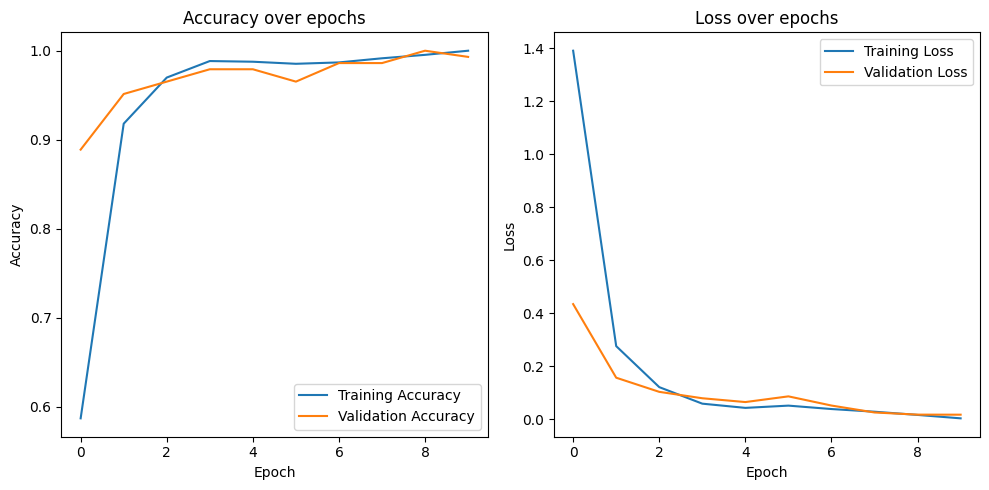

In [6]:
# --------------------------------------------------------------
# Extract training and validation metrics from 'history' object
# --------------------------------------------------------------
# The 'history' object (returned by model.fit) contains the metrics
# recorded at each epoch of training. Here, we extract:
#   - Training accuracy and validation accuracy
#   - Training loss and validation loss
acc = history.history['accuracy']        # Model accuracy during training
val_acc = history.history['val_accuracy']# Model accuracy during validation
loss = history.history['loss']           # Training loss values
val_loss = history.history['val_loss']   # Validation loss values

# --------------------------------------------------------------
# Create a figure to plot Accuracy and Loss side by side
# --------------------------------------------------------------
plt.figure(figsize=(10, 5))  # Set overall figure size (width=10, height=5)

# --------------------------------------------------------------
# Plot Accuracy Graph
# --------------------------------------------------------------
plt.subplot(1, 2, 1)  # Divide figure into 1 row, 2 columns → select first subplot
plt.plot(acc, label='Training Accuracy')       # Plot training accuracy line
plt.plot(val_acc, label='Validation Accuracy') # Plot validation accuracy line
plt.legend()                                   # Display legend labels
plt.title('Accuracy over epochs')              # Title for the first subplot
plt.xlabel('Epoch')                            # X-axis label
plt.ylabel('Accuracy')                         # Y-axis label

# --------------------------------------------------------------
# Plot Loss Graph
# --------------------------------------------------------------
plt.subplot(1, 2, 2)  # Select second subplot (same figure)
plt.plot(loss, label='Training Loss')          # Plot training loss line
plt.plot(val_loss, label='Validation Loss')    # Plot validation loss line
plt.legend()                                   # Display legend labels
plt.title('Loss over epochs')                  # Title for the second subplot
plt.xlabel('Epoch')                            # X-axis label
plt.ylabel('Loss')                             # Y-axis label

# --------------------------------------------------------------
# Adjust layout and display the plots
# --------------------------------------------------------------
plt.tight_layout()  # Adjust spacing between subplots for better readability
plt.show()          # Render the final plots on the screen


In [7]:
# Predict on the first 10 images from the test set
predictions = model.predict(x_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step


W0000 00:00:1775107943.485715   13907 graph_view.cc:850] No registered '' OpKernel for CPU devices compatible with node {{node sequential_1/simple_rnn_1_2/while/body/_39/sequential_1/simple_rnn_1_2/while/simple_rnn_cell_1/Relu}}
	.  Registered:  <no registered kernels>

W0000 00:00:1775107943.490144   13907 graph_view.cc:850] No registered '' OpKernel for CPU devices compatible with node {{node sequential_1/simple_rnn_1/while/body/_1/sequential_1/simple_rnn_1/while/simple_rnn_cell_1/Relu}}
	.  Registered:  <no registered kernels>

E0000 00:00:1775107943.501599   13907 tfg_optimizer_hook.cc:135] tfg_optimizer{any(tfg-consolidate-attrs,tfg-toposort,tfg-shape-inference{graph-version=0},tfg-prepare-attrs-export)} failed: INVALID_ARGUMENT: Node sequential_1/simple_rnn_1_2/while/body/_39/sequential_1/simple_rnn_1_2/while/simple_rnn_cell_1/Relu has an empty op name
	when importing GraphDef to MLIR module in GrapplerHook
E0000 00:00:1775107943.508128   13907 meta_optimizer.cc:967] remapper fai

In [8]:
# Convert predictions from one-hot encoded format to label
predicted_labels = np.argmax(predictions, axis=1)

In [9]:
print("Predicted Labels:", predicted_labels)
print("True Labels:", np.argmax(y_test[:10], axis=1))

Predicted Labels: [6 9 3 7 2 1 5 2 5 3]
True Labels: [6 9 3 7 2 1 5 2 5 2]


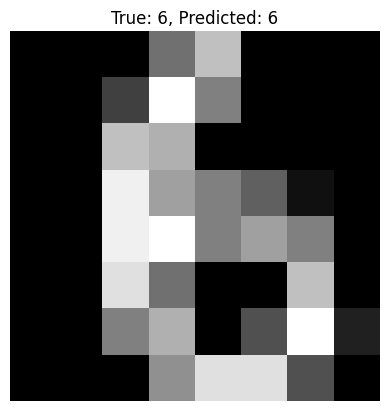

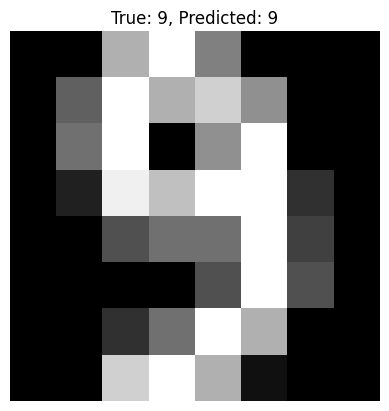

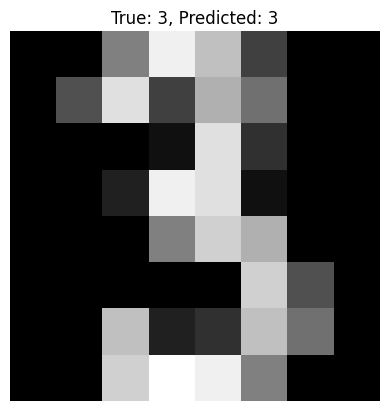

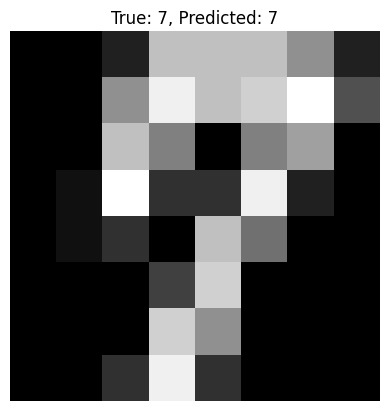

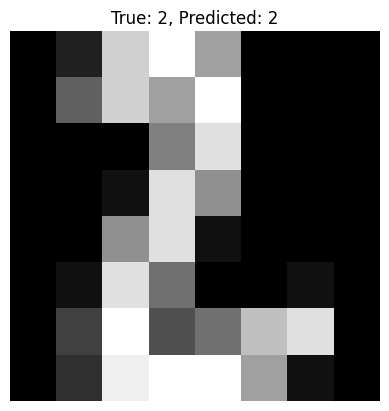

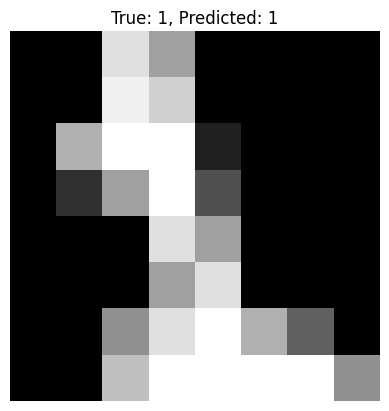

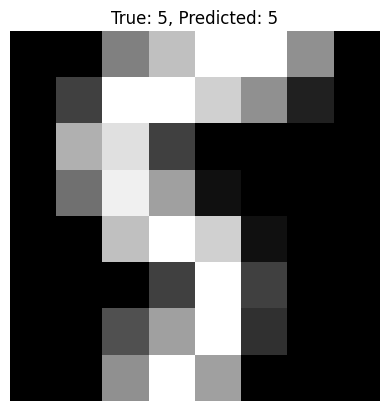

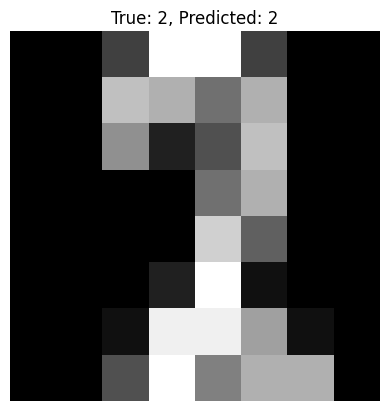

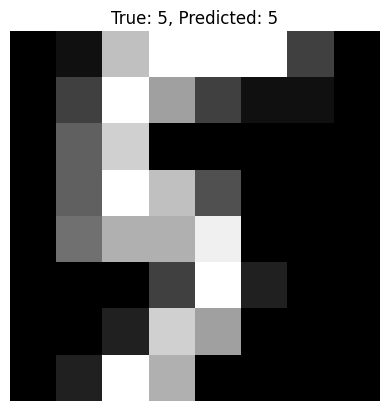

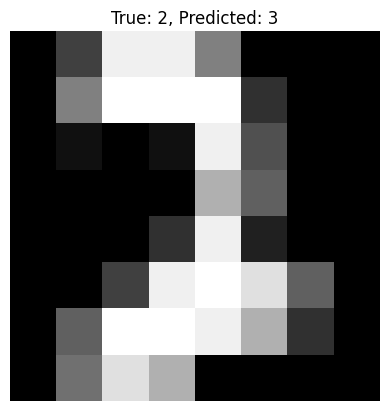

In [10]:
# (Optional) Visualize the predicted images
for i, image in enumerate(x_test[:10]):
    plt.imshow(image.reshape(8, 8), cmap="gray")
    plt.title(f"True: {np.argmax(y_test[i])}, Predicted: {predicted_labels[i]}")
    plt.axis('off')
    plt.show()

In [11]:
# PIL (Pillow) is used for image loading and processing
from PIL import Image

# --------------------------------------------------------------
# Step 1: Load the image you want to classify
# --------------------------------------------------------------
img_path = '3.jpeg'         # Path to your image file (make sure the file exists in this path)
img = Image.open(img_path)  # Open the image using Pillow

# --------------------------------------------------------------
# Step 2: Preprocess the image to match the model’s input format
# --------------------------------------------------------------

# Convert the image to grayscale ('L' mode = luminance)
# The digits dataset used earlier has grayscale 8x8 images, not RGB.
img = img.convert('L')

# Resize the image to 8x8 pixels — same resolution as the digits dataset
img = img.resize((8, 8))

# --------------------------------------------------------------
# Step 3: Convert the image to a numpy array and normalize pixel values
# --------------------------------------------------------------
img_array = np.asarray(img) / 16.0
# Convert the Pillow image into a numpy array
# Divide by 16.0 to scale pixel values approximately into the range 0–16
# (The sklearn digits dataset uses values from 0–16, not 0–255 like normal images)

# --------------------------------------------------------------
# Step 4: Flatten the image and reshape for model input
# --------------------------------------------------------------
img_input = img_array.flatten().reshape(1, 64)
# Flatten converts the 8x8 image into a single vector of 64 values
# Reshape(1, 64) creates a 2D array so the model sees it as one sample with 64 features

# --------------------------------------------------------------
# Step 5: Use the trained RNN model to predict the digit
# --------------------------------------------------------------
prediction = model.predict(img_input)       # Returns an array of probabilities for digits 0–9
predicted_digit = np.argmax(prediction)     # Find the index (0–9) of the highest probability

# --------------------------------------------------------------
# Step 6: Display the predicted result
# --------------------------------------------------------------
print(f"Predicted digit is: {predicted_digit}")
# Print out the model’s predicted digit


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step
Predicted digit is: 6


# **Lab Assignment**
* Retrieve the MNIST dataset using TensorFlow. As a hint, you can use the following import:

```python
from keras.datasets import mnist
```

* Ensure the data is standardized.

* Implement a model using the RNN architecture.

* Train your model.

* Finally, demonstrate the model's performance by displaying test accuracy and loss. Attempt a prediction using an image of your choice.

In [ ]:
# Your solution

